# PCB sine input → pulse duration → FPGA TDC

Configure the **external waveform generator manually**, enter its sine frequency,
**volts peak-to-peak (Vpp)** and DC offset below, then run one finite acquisition.
This notebook controls the FPGA's PCB clock frequency and reads up to **16,384 pulse widths**.
It does not control the external waveform generator and does not use the Red Pitaya ADC.

**Current build:** triggers ≤1 MHz, 50% duty, 4 ns coarse width steps; width fine correction stays OFF.
The loaded implementation has known timing violations. A successful acquisition is a diagnostic
result, not timing closure or an accuracy certification.

### What this test can establish before PCB calibration

Each FPGA rising edge samples the PCB's analogue input; the PCB encodes that sample as
the HIGH duration of its output pulse. The TDC measures PCB rising → falling time.
For a roughly linear PCB transfer, widths should follow a sine at the entered analogue frequency.
We fit width DC, width amplitude and unknown phase at that frequency, compare normalized shape,
and independently search for the dominant measured tone.

The waveform generator and acquisition do **not** share an absolute phase reference.
Fitted phase absorbs generator phase and chain delay; it does not measure propagation delay.
Entered Vpp/offset describe the expected analogue input, not measured/reconstructed volts.
Without PCB voltage→width calibration, this test cannot verify analogue gain, voltage offset
or absolute voltage accuracy. A shape fit alone also cannot prove the chain is correct.

To test the TDC alone, bypass the PCB with a **known compatible digital pulse source** and compare
measured HIGH duration against a scope. A PCB with a known DC analogue input gives another
useful constant-width check. An unconnected analogue input gives no known reference.


## 1. Connect and prepare

| Connection | Purpose |
|---|---|
| E1 pin **5**, DIO1_P → PCB clock | FPGA trigger; positive edge starts the PCB sample |
| PCB **3.3 V digital** output → E1 pin **7**, DIO2_P | TDC single-ended return |
| E1 pin **25 or 26** ↔ PCB ground | Digital common ground |
| External generator output → PCB **analogue input** | Sine stimulus; generator return to PCB analogue ground as specified by PCB |
| E1 pin **1 or 2**, +3.3 V → PCB supply, if applicable | Dedicated power supply; already on |

Use documented header orientation. No E3 launch pair is used here. Do not put a 100 Ω shunt
across the single-ended input. The generator's analogue output goes to the PCB analogue input,
not directly to the FPGA GPIO. Keep analogue voltage within the PCB's established input range.

1. Load the custom bitstream and run the matching rebuilt API/SCPI server (port 5000).
2. Set the external generator to SINE, the chosen frequency/Vpp/offset, and enable its output.
   Match its load setting to the actual connection; verify the voltage at the PCB input with a scope.
3. Check the PCB trigger and return with a scope. Each return must finish within its FPGA clock
   cycle, including PCB response delay; aim for HIGH/LOW intervals ≥8 ns. Constant HIGH/100% duty
   merges pulses and should produce saturation/missing-edge flags.
4. Close other clients that might reconfigure the pulse/TDC. The notebook owns these settings
   during capture and leaves the FPGA pulse output OFF afterward. The optional continuous-clock
   cell near the end intentionally leaves it running when enabled.

Use **Restart Kernel and Run All** after changing the helper code. Install missing plotting
dependencies in this notebook kernel with `%pip install numpy matplotlib` if needed.


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Supports a kernel started in the repository root or in scpi-tests/.
test_dir = next((p for p in (Path.cwd(), Path.cwd() / "scpi-tests")
                 if (p / "tdc_sine_tools.py").is_file()), None)
if test_dir is None:
    raise FileNotFoundError("Start the kernel in RedPitaya_app or scpi-tests; keep both helper .py files beside this notebook")
sys.path.insert(0, str(test_dir.resolve()))
from tdc_sine_tools import (
    validate_config, acquire_width_burst, save_capture, analyze_capture,
    decode_bits, STATUS_BITS, stop_output, sine_values,
)
print("Helpers:", test_dir.resolve())


Helpers: C:\Users\kairan\vscodeprj\RedPitaya_app\scpi-tests


## 2. Enter your external generator settings and FPGA clock rate

The numbers below are **examples**, not a statement of your PCB's allowed voltage range.
`sine_vpp=1.0` means ±0.5 V about the entered offset. At offset 0.5 V, the ideal input range
is 0…1 V. Enter Vpp, not peak amplitude or Vrms.

Start with ≥10 FPGA samples per sine cycle and ≥5 sine cycles per capture.
Example: 100 kHz FPGA clock, 1 kHz analogue sine, 16,384 samples gives about 164 sine cycles.
The actual FPGA frequency is quantized to its timing grid and is used for all analysis.


In [22]:
CONFIG = {
    "host": "169.254.77.151",
    "port": 5000,
    "fpga_frequency_hz": 100_000.0,  # PCB clock / sample rate; current width build <=1 MHz
    "sample_count": 16_384,          # 1..16384; use at least 32 for sine fitting
    "input_mode": "SINGLE",         # E1 pin 7; LVDS alternative requires different wiring
    "sine_frequency_hz": 1_000.0,    # Set these three values manually on the external generator
    "sine_vpp": 0.4,                # Volts PEAK-TO-PEAK at PCB analogue input
    "sine_offset_v": 0.4,
    "settle_s": 0.1,                # FPGA clock runs for this long before ARM
    "timeout_s": 20.0,              # Must exceed requested capture duration + margin
}
PLOT_SINE_CYCLES = 5                 # Plots zoom to first few cycles; fitting uses the full burst
SAVE_DIRECTORY = test_dir / "tdc_sine_results"

plan = validate_config(CONFIG)
print(f"FPGA: requested {CONFIG['fpga_frequency_hz']:g} Hz; actual {plan['actual_fpga_hz']:.9g} Hz")
print(f"PULSE:TIMING {plan['period_ns']},{plan['high_ns']} (ns, 50% duty)")
print(f"Capture: {CONFIG['sample_count']} records, nominal {plan['duration_s']*1000:.3f} ms")
print(f"Sine: {plan['samples_per_sine_cycle']:.2f} samples/cycle; {plan['sine_cycles']:.2f} cycles/burst")
print(f"Entered analogue range: {CONFIG['sine_offset_v']-CONFIG['sine_vpp']/2:g} to "
      f"{CONFIG['sine_offset_v']+CONFIG['sine_vpp']/2:g} V (reference only)")
if plan['samples_per_sine_cycle'] < 10 or plan['sine_cycles'] < 5:
    print("CAUTION: use >=10 samples/cycle and >=5 cycles/burst for a useful sine comparison.")


FPGA: requested 100000 Hz; actual 100000 Hz
PULSE:TIMING 10000,5000 (ns, 50% duty)
Capture: 16384 records, nominal 163.840 ms
Sine: 100.00 samples/cycle; 163.84 cycles/burst
Entered analogue range: 0.2 to 0.6 V (reference only)


## 3. Acquire one burst — this cell contacts the board

Confirm that the external generator is running with the settings above, then execute this cell.
The FPGA clock starts **before** ARM so the stopped-trigger watchdog does not include a network
round trip. The script disables legacy TDC/internal/MMCM sources, selects the external return,
and disables width fine correction. `TDC:ENABLE OFF` is intentional: WIDTH:ARM controls the new engine.

Results are frozen after capture and read in chunks of ≤128 records. The clock is stopped before
readout. Invalid frames are saved with their original cycle IDs; they are never replaced by zero
volts or removed from the time axis. CSV + JSON metadata are written before fitting.

A normal DONE status is 0x08; inspect any error flags. A cleanup warning means output OFF was
not fully confirmed. If a connection fails, inspect the hardware and use the separate stop cell below.


In [23]:
# Clear old variables first so a failed rerun cannot reuse a previous result.
capture = analysis = saved_stem = None
capture = acquire_width_burst(CONFIG)
saved_stem = save_capture(capture, SAVE_DIRECTORY)
print(f"Status: 0x{capture['status']:02x} ({decode_bits(capture['status'], STATUS_BITS)})")
print(f"Records: {len(capture['records'])}/{CONFIG['sample_count']}; valid: {capture['valid_count']}; "
      f"invalid: {len(capture['records'])-capture['valid_count']}")
print(f"Hardware capacity: {capture['capacity']}; coarse tick: {capture['tick_ps']} ps")
print("Flag counts:", json.dumps(capture['flag_counts'], indent=2))
print("Saved raw data:", saved_stem.with_suffix('.csv').resolve())
print("Saved settings:", saved_stem.with_suffix('.json').resolve())
print("First records: cycle, flags, coarse_ticks, rise_raw, fall_raw, width_ps")
for row in capture['records'][:8]:
    print(row, decode_bits(row[1]))
if not capture['acquisition_ok']:
    raise RuntimeError("Acquisition error/incomplete burst. Raw data saved; inspect status and wiring before fitting.")
if capture['valid_count'] != len(capture['records']):
    print("Some pulses are invalid. They remain in the saved data and will be excluded from fits at their original times.")


Status: 0x08 (DONE)
Records: 16384/16384; valid: 16384; invalid: 0
Hardware capacity: 16384; coarse tick: 4000 ps
Flag counts: {
  "VALID": 16384,
  "EXTRA_EDGES": 57,
  "SATURATED": 1,
  "COARSE_ONLY": 14336,
  "FINE_INVALID": 2032
}
Saved raw data: C:\Users\kairan\vscodeprj\RedPitaya_app\scpi-tests\tdc_sine_results\tdc_pcb_sine_20261016T134802_351244Z.csv
Saved settings: C:\Users\kairan\vscodeprj\RedPitaya_app\scpi-tests\tdc_sine_results\tdc_pcb_sine_20261016T134802_351244Z.json
First records: cycle, flags, coarse_ticks, rise_raw, fall_raw, width_ps
(1, 553715729, 1241, 34, 240, 4964000) VALID|EXTRA_EDGES|SATURATED
(2, 16843009, 1240, 198, 112, 4960000) VALID|COARSE_ONLY
(3, 16843009, 1240, 150, 112, 4960000) VALID|COARSE_ONLY
(4, 553713921, 1240, 101, 109, 4960000) VALID|COARSE_ONLY
(5, 553713921, 1240, 42, 112, 4960000) VALID|COARSE_ONLY
(6, 16843009, 1239, 194, 112, 4956000) VALID|COARSE_ONLY
(7, 553713921, 1239, 128, 113, 4956000) VALID|COARSE_ONLY
(8, 16843009, 1239, 53, 112, 49

## 4. Fit shape and estimate frequency

The fixed-frequency fit is `width_ns = DC + A*sin(2π*f_entered*t + phase)`.
Only DC, amplitude and phase are fitted here; **the entered frequency is not adjusted**.
Normalized samples are `(width_ns - fitted_DC)/fitted_A`. R² near 1 and small normalized RMSE
mean a sine at that frequency describes the widths well; no automatic hardware PASS is inferred.

A separate FFT candidate search and sine refinement estimate the strongest measured tone
**without using the entered frequency**. It can expose a wrong frequency setting. Distortion,
aliasing or many invalid frames can make the strongest tone differ from the fundamental.
FFT bin spacing and estimation residuals are diagnostics, not certified frequency uncertainty.

There is no clock synchronization to the analogue generator, so we phase-align the reference.
Do not interpret the fitted phase as latency. Both clipping/nonlinearity and FPGA timing failures
can produce residuals; compare with an oscilloscope to distinguish them.


In [24]:
if capture is None:
    raise RuntimeError("Run acquisition first")
analysis = None
analysis = analyze_capture(capture)
fixed = analysis['fixed_fit']
dominant = analysis['dominant_fit']
entered_hz = capture['settings']['sine_frequency_hz']
summary = {
    "entered_sine_hz": entered_hz,
    "dominant_measured_tone_hz": dominant['frequency_hz'],
    "dominant_minus_entered_hz": dominant['frequency_hz']-entered_hz,
    "dominant_minus_entered_percent": 100*(dominant['frequency_hz']/entered_hz-1),
    "fft_bin_spacing_hz": capture['plan']['actual_fpga_hz']/len(capture['records']),
    "fixed_frequency_width_dc_ns": fixed['offset'],
    "fixed_frequency_width_amplitude_ns": fixed['amplitude'],
    "fixed_frequency_width_rmse_ns": fixed['rmse'],
    "fixed_frequency_r_squared": analysis['r_squared'],
    "fixed_frequency_normalized_rmse": analysis['normalized_rmse'],
    "dominant_tone_fit_rmse_ns": dominant['rmse'],
    "phase_alignment_rad_not_latency": fixed['phase_rad'],
    "valid_records": int(np.count_nonzero(analysis['valid'])),
    "notes": analysis['notes'],
    "interpretation": "Uncalibrated shape/frequency comparison; entered generator Vpp/offset are not measured volts.",
}
print(json.dumps(summary, indent=2))
if saved_stem is not None:
    analysis_path = saved_stem.with_suffix('.analysis.json')
    analysis_path.write_text(json.dumps(summary, indent=2, allow_nan=False), encoding='utf-8')
    print("Saved analysis:", analysis_path.resolve())
for note in analysis['notes']:
    print("NOTE:", note)


{
  "entered_sine_hz": 1000.0,
  "dominant_measured_tone_hz": 1000.0073872354194,
  "dominant_minus_entered_hz": 0.007387235419400895,
  "dominant_minus_entered_percent": 0.0007387235419376026,
  "fft_bin_spacing_hz": 6.103515625,
  "fixed_frequency_width_dc_ns": 4925.068862647891,
  "fixed_frequency_width_amplitude_ns": 56.784888650471004,
  "fixed_frequency_width_rmse_ns": 15.123996123549926,
  "fixed_frequency_r_squared": 0.8756727244105376,
  "fixed_frequency_normalized_rmse": 0.26633839535449155,
  "dominant_tone_fit_rmse_ns": 15.12373847785516,
  "phase_alignment_rad_not_latency": 2.3123362723475656,
  "valid_records": 16384,
  "notes": [],
  "interpretation": "Uncalibrated shape/frequency comparison; entered generator Vpp/offset are not measured volts."
}
Saved analysis: C:\Users\kairan\vscodeprj\RedPitaya_app\scpi-tests\tdc_sine_results\tdc_pcb_sine_20261016T134802_351244Z.analysis.json


## 5. Compare the captured signal with the entered sine

The top panel shows **expected input volts**, computed from your entered settings and the fitted
phase. It is not a measurement of PCB input voltage. Lower panels show measured widths and the
normalized comparison. Fits and summary statistics use the entire burst, even when plots are zoomed.
Red marks indicate invalid frames at their actual trigger-cycle times.


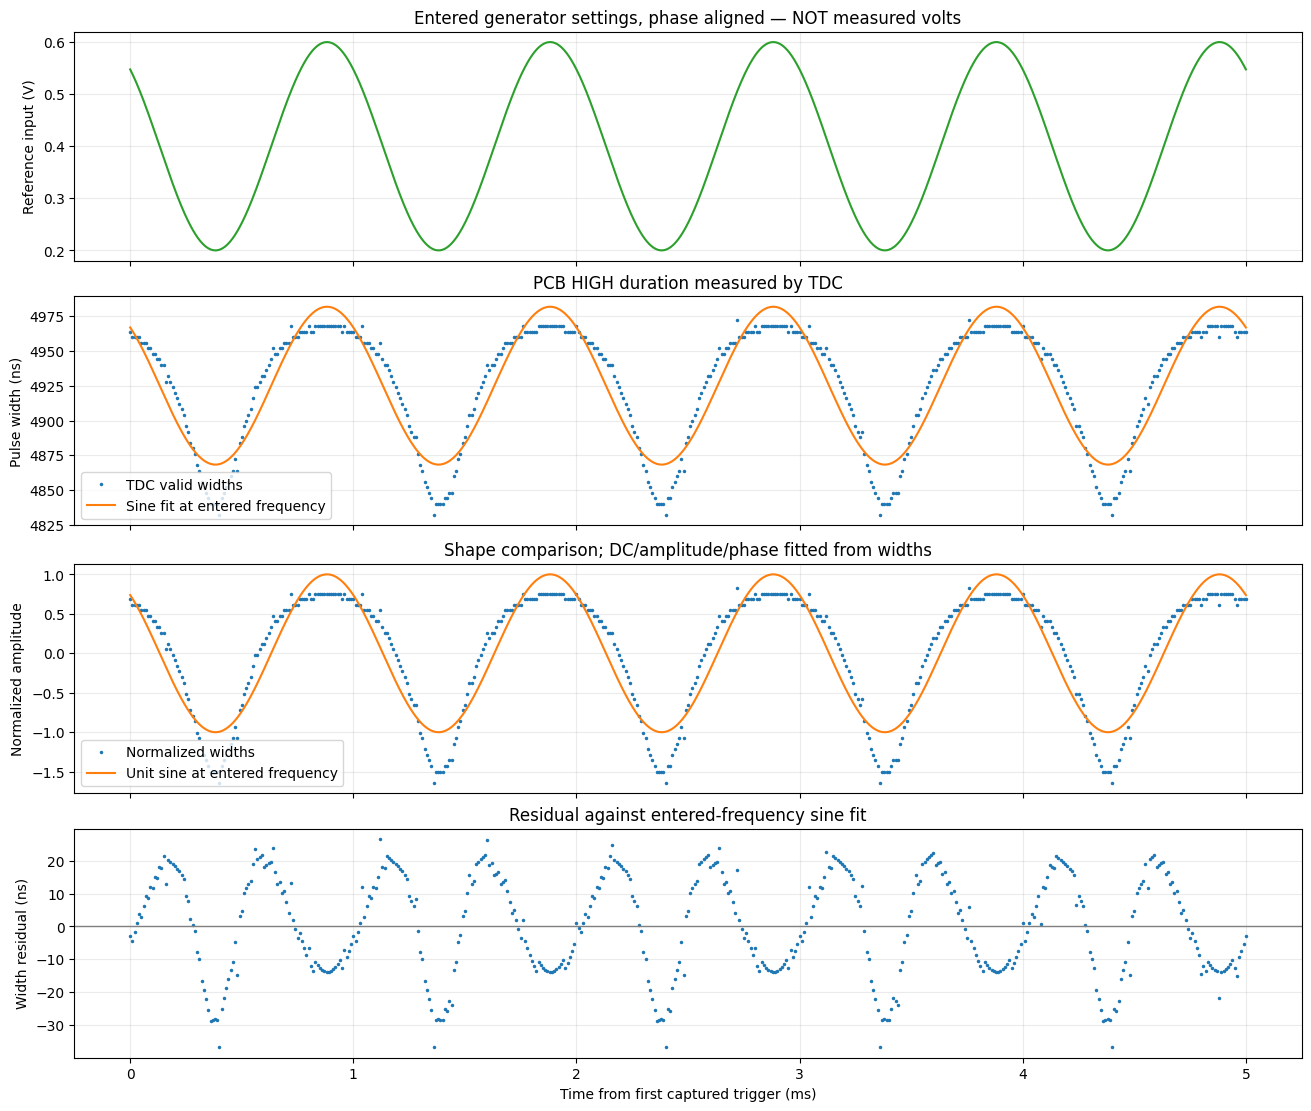

In [25]:
if analysis is None:
    raise RuntimeError("Run sine analysis first")
settings = capture['settings']  # Use the settings saved with this capture, not later CONFIG edits
t = analysis['time_s']
valid = analysis['valid']
fixed = analysis['fixed_fit']
view_s = min(t[-1], PLOT_SINE_CYCLES/settings['sine_frequency_hz'])
dense_t = np.linspace(0, view_s, 2500)
reference_dense = np.sin(2*np.pi*settings['sine_frequency_hz']*dense_t + fixed['phase_rad'])
reference_v = settings['sine_offset_v'] + settings['sine_vpp']/2 * reference_dense
plot_mask = t <= view_s
width_for_plot = np.where(valid, analysis['width_ns'], np.nan)

fig, axes = plt.subplots(4, 1, figsize=(13, 11), sharex=True, constrained_layout=True)
axes[0].plot(dense_t*1e3, reference_v, color='tab:green')
axes[0].set(ylabel='Reference input (V)', title='Entered generator settings, phase aligned — NOT measured volts')
axes[1].plot(t[plot_mask]*1e3, width_for_plot[plot_mask], '.', ms=3, label='TDC valid widths')
axes[1].plot(dense_t*1e3, sine_values(dense_t, fixed), label='Sine fit at entered frequency')
axes[1].set(ylabel='Pulse width (ns)', title='PCB HIGH duration measured by TDC')
axes[1].legend()
axes[2].plot(t[plot_mask]*1e3, analysis['normalized_width'][plot_mask], '.', ms=3, label='Normalized widths')
axes[2].plot(dense_t*1e3, reference_dense, label='Unit sine at entered frequency')
axes[2].set(ylabel='Normalized amplitude', title='Shape comparison; DC/amplitude/phase fitted from widths')
axes[2].legend()
axes[3].plot(t[plot_mask]*1e3, analysis['residual_ns'][plot_mask], '.', ms=3)
axes[3].axhline(0, color='gray', lw=1)
bad = plot_mask & ~valid
if np.any(bad):
    axes[3].plot(t[bad]*1e3, np.zeros(np.count_nonzero(bad)), 'rx', label='Invalid frame (not zero residual)')
    axes[3].legend()
axes[3].set(xlabel='Time from first captured trigger (ms)', ylabel='Width residual (ns)',
            title='Residual against entered-frequency sine fit')
for ax in axes:
    ax.grid(alpha=0.25)
if saved_stem is not None:
    fig.savefig(saved_stem.with_suffix('.waveforms.png'), dpi=160)
plt.show()


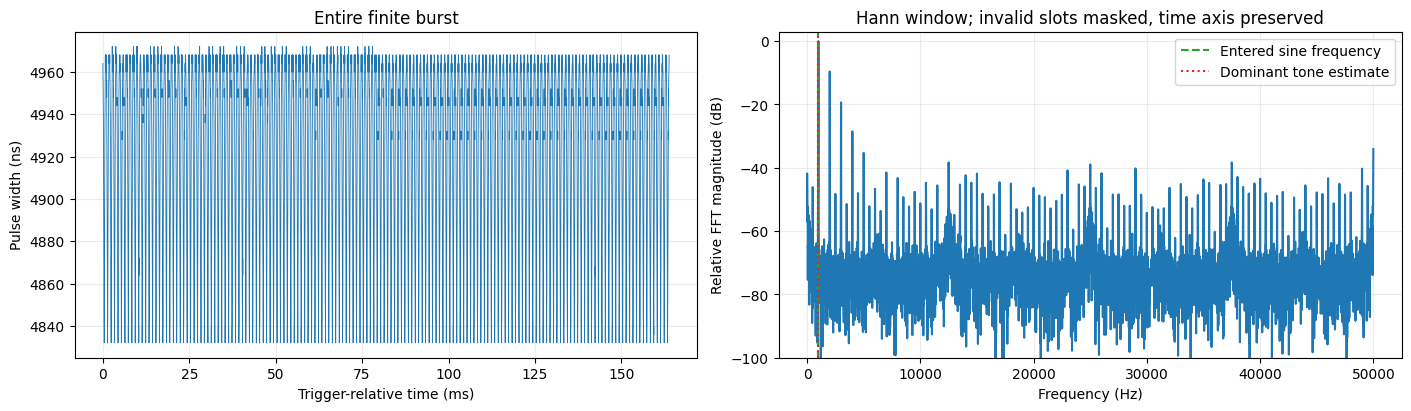

In [26]:
# Full-burst width trace and spectrum; no concatenation of separate captures.
fig, axes = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)
axes[0].plot(t*1e3, width_for_plot, lw=0.6)
axes[0].set(xlabel='Trigger-relative time (ms)', ylabel='Pulse width (ns)', title='Entire finite burst')
mag = analysis['fft_magnitude']
relative_db = 20*np.log10(np.maximum(mag/max(float(np.max(mag)), 1e-30), 1e-12))
axes[1].plot(analysis['fft_hz'], relative_db)
axes[1].axvline(settings['sine_frequency_hz'], color='tab:green', ls='--', label='Entered sine frequency')
axes[1].axvline(analysis['dominant_fit']['frequency_hz'], color='tab:red', ls=':', label='Dominant tone estimate')
axes[1].set(xlabel='Frequency (Hz)', ylabel='Relative FFT magnitude (dB)', ylim=(-100, 3),
            title='Hann window; invalid slots masked, time axis preserved')
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.25)
if saved_stem is not None:
    fig.savefig(saved_stem.with_suffix('.spectrum.png'), dpi=160)
plt.show()


## 6. Interpret results / next experiments

- **No records / global timeout:** check running FPGA clock, matching API/server and trigger ownership.
- **NO_RISE / NO_FALL / HIGH_AT_START / SATURATED:** check selected return, PCB power, clock response,
  voltage range, and whether the pulse actually ends within its trigger cycle.
- **EXTRA_EDGES:** inspect ringing, extra pulses, thresholds and signal integrity with a scope.
- **OVERFLOW / RATE_ERROR:** respect ≤1 MHz and 50% drive duty; keep the current timing failures in mind.
- **Contradictory record flags:** VALID together with frame errors, missing width mode, or
  width/count mismatches indicate corrupt/inconsistent acquisition. Updated helpers reject
  these before fitting, even when the hardware VALID bit is set. Updated API/server builds
  reject them in DATA?; DATA:RAW? is available separately for diagnosis.
- **COARSE_ONLY:** expected; 4 ns coarse steps are used. **FINE_INVALID** can coexist with a valid coarse
  width; it describes the carry-code snapshot, not necessarily a missing pulse.
- **Flat width:** verify the sine at the PCB input and modulation on the PCB pulse output. A flat signal
  cannot be sine-fitted. The notebook will report this rather than divide by zero.
- **Wrong dominant frequency:** check generator frequency, entered units, aliasing and harmonic distortion.
- **Correct frequency but large residual:** inspect PCB transfer nonlinearity/clipping, timing failures,
  quantization and analogue noise. R² is a fit diagnostic, not proof of absolute accuracy.

Start with a slow analogue sine and 100 kHz FPGA clock. Compare widths against a scope at several DC
voltages and sine amplitudes. Change FPGA frequency in CONFIG and rerun the plan/acquisition/analysis
cells. Do not join independent bursts into one continuous trace: their inter-burst phase is unknown.

After implementation timing is repaired, measure the PCB voltage→width transfer if reconstruction in
volts is needed. FPGA fine-time interpolation requires separate measured rising/falling calibration for
this placed 250 MHz width path; the old legacy TDC calibration is not interchangeable.

CSV stores every raw record, flags, original trigger-relative time and width. JSON stores the settings,
actual trigger period, capture status and caveats; analysis JSON and PNG plots are saved beside them.
The external analogue generator is not turned off by this notebook.


## Optional: continuous clock only on DIO1_P

Set `CLOCK_FREQUENCY_HZ` and run the next cell to output a continuous **50% duty** clock
on **DIO1_P, E1 pin 5** (ground: E1 pin 25 or 26). It can run by itself without the
sine setup cells, NumPy, or a TDC acquisition. The host defaults to CONFIG when available.

The clock **keeps running after the cell finishes**, including if this cell is reached by
Run All. Set `CLOCK_ENABLED = False` and rerun this same cell to stop it, leaving the pin LOW.
Rerunning with a new frequency briefly stops the output while applying the timing.
Frequency is rounded to the nearest supported 4 ns period; actual frequency is printed.
This separate setting does not change CONFIG or start sine capture. The acquisition cell
will apply its own configured frequency and stop the clock when capture finishes.


In [2]:
# Standalone clock control: edit these settings, then run this cell.
CLOCK_FREQUENCY_HZ = 100_000.0
CLOCK_ENABLED = True              # False + rerun = stop clock, pin held LOW
CLOCK_HOST = globals().get("CONFIG", {}).get("host", "169.254.77.151")
CLOCK_PORT = globals().get("CONFIG", {}).get("port", 5000)

import math
import sys
from pathlib import Path

# Reuse the existing standard-library SCPI client; no sine helpers required.
_clock_dir = next((p for p in (Path.cwd(), Path.cwd() / "scpi-tests")
                   if (p / "tdc_pulse_width_test.py").is_file()), None)
if _clock_dir is None:
    raise FileNotFoundError("Start the kernel in RedPitaya_app or scpi-tests")
if str(_clock_dir.resolve()) not in sys.path:
    sys.path.insert(0, str(_clock_dir.resolve()))
from tdc_pulse_width_test import Client as _ClockClient

if CLOCK_ENABLED:
    if not math.isfinite(CLOCK_FREQUENCY_HZ) or not 0 < CLOCK_FREQUENCY_HZ <= 250_000_000:
        raise ValueError("CLOCK_FREQUENCY_HZ must be finite, positive and <=250 MHz")
    _clock_period_ns = round(1e9 / CLOCK_FREQUENCY_HZ / 4) * 4
    if not 4 <= _clock_period_ns <= 8_589_934_588:
        raise ValueError("Requested clock period is outside the pulse generator range")
    _clock_high_ns = _clock_period_ns // 2

_clock_client = _ClockClient(CLOCK_HOST, CLOCK_PORT)
try:
    _clock_client.write("PULSE:OUTPUT OFF")
    if _clock_client.query("PULSE:OUTPUT?") != "0":
        raise RuntimeError("Clock OFF was not confirmed")
    _clock_client.check()
    if CLOCK_ENABLED:
        _clock_pin = _clock_client.query("PULSE:PIN?")
        _clock_client.check()
        if _clock_pin != "DIO1_P":
            raise RuntimeError(f"Unexpected pulse output pin: {_clock_pin}")
        _clock_client.write(f"PULSE:TIMING {_clock_period_ns},{_clock_high_ns}")
        _clock_timing = _clock_client.query("PULSE:TIMING?")
        _clock_client.check()
        if tuple(map(int, _clock_timing.split(','))) != (_clock_period_ns, _clock_high_ns):
            raise RuntimeError(f"Unexpected timing readback: {_clock_timing}")
        _clock_client.write("PULSE:OUTPUT ON")
        if _clock_client.query("PULSE:OUTPUT?") != "1":
            raise RuntimeError("Clock ON was not confirmed")
        _clock_client.check()
        print(f"DIO1_P (E1 pin 5): clock ON, requested {CLOCK_FREQUENCY_HZ:g} Hz, "
              f"actual {1e9 / _clock_period_ns:.9g} Hz, duty 50%")
        print(f"Period {_clock_period_ns} ns; HIGH {_clock_high_ns} ns. "
              "Set CLOCK_ENABLED=False and rerun to stop.")
    else:
        print("DIO1_P clock OFF; pin held LOW.")
except BaseException:
    try:
        _clock_client.write("PULSE:OUTPUT OFF")
    except Exception as _clock_stop_error:
        print(f"Could not confirm clock cleanup: {_clock_stop_error}")
    raise
finally:
    _clock_client.close()       # Closing SCPI leaves a successfully started clock running.


DIO1_P (E1 pin 5): clock ON, requested 100000 Hz, actual 100000 Hz, duty 50%
Period 10000 ns; HIGH 5000 ns. Set CLOCK_ENABLED=False and rerun to stop.


## Optional emergency stop / recovery

The acquisition function already attempts OFF and ABORT in `finally`. Run the following cell
separately after an interrupted acquisition if necessary. If the board is unreachable, software
cannot confirm output state: reconnect or stop the hardware and check the trigger with a scope.


In [ ]:
# Uncomment and run to explicitly stop the FPGA clock and abort width capture.
# stop_output(CONFIG['host'], CONFIG['port'])
# print('FPGA pulse output confirmed OFF; width engine idle')
